
# Module 4 — EOF and PRINCIPAL COMPONENT

**Author:** deffip2@illinois.edu

### Objective: Implementing the deseasonalization into data timeseries and apply it into EOF dan PC analysis

This notebook:
1) Loads **Monthly ERA5 Renalaysis** data from the GDEX UCAR for the Pacific Ocean.

2) Detrend and deseasonalized the data

3) Computes **EOF**

> Data source: `https://osdf-data.gdex.ucar.edu/ncar/gdex/d633001/e5.moda.an.sfc/`

In [46]:
import pandas as pd
import xarray as xr
import numpy as np
import dask
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1. **Data Loading**

We use the monthly ERA5 reanalysis data from single level for three following variables:
1. Sea surface temperature
2. total column water vapor
3. land sea mask

The three datasets are subjected to a resolution change (from 0.25° to 1°) and the land areas are masked out.
The processed data are then stored in a single NetCDF file that includes all three variables for further analysis.


**This first section only needs to be run once, after the data have been successfully stored.**

In [ ]:
BASE = "https://osdf-data.gdex.ucar.edu/ncar/gdex/d633001/e5.moda.an.sfc/"
PATTERN = "e5.moda.an.sfc.{code}.ll025sc.{start}_{end}.nc"

CODES = {
    "sst":  "128_034_sstk",  # sea surface temperature
    "tcwv": "128_137_tcwv",  # total column water vapour 
    "lsm":  "128_172_lsm",   # land-sea mask
}

# 1979 to 2022
YEARS = range(1979, 2023)

def build_urls(code: str) -> list[str]:
    files = []
    for y in YEARS:
        start = f"{y}010100"
        end   = f"{y}120100"
        fname = PATTERN.format(code=code, start=start, end=end)
        files.append(f"{BASE}{y}/{fname}")
    return files

files_sst  = build_urls(CODES["sst"])
files_tcwv = build_urls(CODES["tcwv"])
files_lsm  = build_urls(CODES["lsm"])


In [ ]:
ds_sst = xr.open_mfdataset(
    files_sst,
    engine="h5netcdf",
    combine="by_coords",
    chunks={"time": 12},
    parallel=False,
)

ds_tcwv = xr.open_mfdataset(
    files_tcwv,
    engine="h5netcdf",
    combine="by_coords",
    chunks={"time": 12},
    parallel=False,
)

ds_lsm = xr.open_mfdataset(
    files_lsm,
    engine="h5netcdf",
    combine="by_coords",
    chunks={"time": 12},
    parallel=False,
)

In [7]:
ds_lsm

<xarray.Dataset> Size: 2GB
Dimensions:    (time: 528, latitude: 721, longitude: 1440)
Coordinates:
  * latitude   (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude  (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2022-12-01
Data variables:
    LSM        (time, latitude, longitude) float32 2GB dask.array<chunksize=(12, 389, 776), meta=np.ndarray>
    utc_date   (time) int32 2kB dask.array<chunksize=(12,), meta=np.ndarray>
Attributes:
    DATA_SOURCE:          ECMWF: https://cds.climate.copernicus.eu, Copernicu...
    NETCDF_CONVERSION:    CISL RDA: Conversion from ECMWF GRIB 1 data to netC...
    NETCDF_VERSION:       4.6.1
    CONVERSION_PLATFORM:  Linux casper02 3.10.0-693.21.1.el7.x86_64 #1 SMP We...
    CONVERSION_DATE:      Mon Nov 11 07:48:33 MST 2019
    Conventions:          CF-1.6
    NETCDF_COMPRESSION:   NCO: Precision-preserving compression to netCDF4/HD...
    history:              Mon Nov 11 07:48:34 2019: ncks -4 --ppc default=7 e...
    NCO:                  netCDF Operators version 4.7.9 (Homepage = http://n...

Part of the section where we slice the data for the Pacific Ocean only and coarsen the spatial resolution into 1 degree 

In [ ]:

# Pacific ocean: lon 120E to 60 W (300), lat 65 to -65
lat, lon = "latitude", "longitude"

box = {lat: slice(65, -65), lon: slice(120, 300)}
sst  = ds_sst['SSTK'].sel(box)
tcwv = ds_tcwv['TCWV'].sel(box)
lsm  = ds_lsm['LSM'].sel(box)

# Coarsen the spatial res. 
factor = {lat: 4, lon: 4}
sst_1deg  = sst.coarsen(factor, boundary="trim").mean()
tcwv_1deg = tcwv.coarsen(factor, boundary="trim").mean()
lsm_1deg  = lsm.coarsen(factor, boundary="trim").mean()

# Maskout the land 
sst_1deg  = sst_1deg.squeeze(drop=True).rename("sst")
tcwv_1deg = tcwv_1deg.squeeze(drop=True).rename("tcwv")
lsm_1deg  = lsm_1deg.squeeze(drop=True).rename("lsm")

ocean_mask = lsm_1deg < 0.5
sst_1deg_ocean  = sst_1deg.where(ocean_mask)
tcwv_1deg_ocean = tcwv_1deg.where(ocean_mask)

ds = xr.Dataset({
    "sst": sst_1deg_ocean,
    "tcwv": tcwv_1deg_ocean,
    "lsm": lsm_1deg
})

In [10]:
ds

<xarray.Dataset> Size: 148MB
Dimensions:    (latitude: 130, longitude: 180, time: 528)
Coordinates:
  * latitude   (latitude) float64 1kB 64.62 63.62 62.62 ... -62.38 -63.38 -64.38
  * longitude  (longitude) float64 1kB 120.4 121.4 122.4 ... 297.4 298.4 299.4
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2022-12-01
Data variables:
    sst        (time, latitude, longitude) float32 49MB dask.array<chunksize=(12, 72, 74), meta=np.ndarray>
    tcwv       (time, latitude, longitude) float32 49MB dask.array<chunksize=(12, 72, 74), meta=np.ndarray>
    lsm        (time, latitude, longitude) float32 49MB dask.array<chunksize=(12, 72, 74), meta=np.ndarray>

In [11]:
with dask.config.set(scheduler="single-threaded"):
    ds.chunk({}).to_netcdf(
        "/data/keeling/a/deffip2/ATMS_523/HW_4_Module_4/ATMS-523-Module-4-deffip2/ERA5_data/pacific_monthly_1deg_ocean.nc",
        engine="h5netcdf",
    )

# 2. Detrend, deseasonalize and strandarization

This step performs **detrending** and **deseasonalization** by calculating the monthly data relative to the reference period (1981–2010).

In [4]:
# Load the stored data from the first section
ds  = xr.open_dataset("/data/keeling/a/deffip2/ATMS_523/HW_4_Module_4/ATMS-523-Module-4-deffip2/ERA5_data/pacific_monthly_1deg_ocean.nc")

In [5]:
ds

<xarray.Dataset> Size: 148MB
Dimensions:    (time: 528, latitude: 130, longitude: 180)
Coordinates:
  * latitude   (latitude) float64 1kB 64.62 63.62 62.62 ... -62.38 -63.38 -64.38
  * longitude  (longitude) float64 1kB 120.4 121.4 122.4 ... 297.4 298.4 299.4
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2022-12-01
Data variables:
    sst        (time, latitude, longitude) float32 49MB ...
    tcwv       (time, latitude, longitude) float32 49MB ...
    lsm        (time, latitude, longitude) float32 49MB ...

In [2]:
# Copied from HW.md 

def _time_as_float(time: xr.DataArray, time_dim: str) -> xr.DataArray:
    t0 = time.isel({time_dim: 0})
    return (time - t0).astype("timedelta64[s]").astype("float64")


def linear_detrend(obj: xr.DataArray | xr.Dataset, time_dim: str = "time") -> xr.DataArray | xr.Dataset:
    """
    Remove a linear trend y ~ s*(t - t̄_valid) + ȳ_valid at each grid point.
    Closed-form LS using reductions; dask-friendly; handles NaNs.
    """
    t = _time_as_float(obj.coords[time_dim], time_dim)


    def _detrend_da(da: xr.DataArray) -> xr.DataArray:
        da = da.sortby(time_dim).astype("float32")
        if hasattr(da.data, "chunks"):
            da = da.chunk({time_dim: -1})
        mask = da.notnull()
        t_b = t.broadcast_like(da)
        t_mean_valid = t_b.where(mask).mean(time_dim, skipna=True)
        tc = t_b - t_mean_valid
        num = (da * tc).sum(time_dim, skipna=True)
        den = (tc**2).sum(time_dim, skipna=True)
        slope = xr.where(den > 0, num / den, 0.0)
        ybar = da.mean(time_dim, skipna=True)
        trend = slope * (t_b - t_mean_valid) + ybar
        return (da - trend).astype("float32")

    return obj.map(_detrend_da) if isinstance(obj, xr.Dataset) else _detrend_da(obj)

def monthly_anom_and_z(
    detr: xr.DataArray | xr.Dataset,
    time_dim: str = "time",
    base_period: tuple[str, str] | None = None,
    ddof: int = 1,
    eps: float = 1e-6,
):
    """
    From linearly-detrended data, remove monthly climatology and compute monthly z-scores.
    Returns (anom, z). Works for Dataset or DataArray.
    """
    clim_src = detr if base_period is None else detr.sel({time_dim: slice(*base_period)})
    key = f"{time_dim}.month"

    clim_mean = clim_src.groupby(key).mean(time_dim, skipna=True)
    anom = detr.groupby(key) - clim_mean

    clim_std = clim_src.groupby(key).std(time_dim, skipna=True, ddof=ddof)
    safe_std = xr.where(clim_std > eps, clim_std, np.nan)
    z = anom.groupby(key) / safe_std
    return anom, z

In [6]:
# detrend + deseasonalize application
detr = linear_detrend(ds, time_dim="time")
anom, z = monthly_anom_and_z(detr, time_dim="time",
                             base_period=("1981-01-01", "2010-12-31")) 
print(list(z.data_vars))

/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/p

['sst', 'tcwv', 'lsm']


# 3. EOF Analysis

In this step, we apply EOF and PC:

**EOF computation:**  
  Using the eofs solver, the SST anomalies are decomposed into spatial patterns (EOFs) and their temporal pattern (PCs).

**First five EOFs:**  
  The first five EOF spatial patterns were extracted and plotted to highlight the dominant modes of SST variability.

**Variance:**  
  The percentage of variance explained by the leading 10 modes was computed using.

**Reconstrucyion:**  
  Reconstruct the SST anomalies by employing the first five dominant modes and compare it with the observation.

**The correlation between EOF Mode 1 and Standarized TCWV:**  
  Examine the potential relation between warming/cooling and moistening/drying

In [7]:
from eofs.xarray import Eof

"""
In this part we need to transpose the data because our initial data has latitude, longitude and time respectively. 
We need to change the order and put the 'time' coordinate first.
"""
sst_anom = anom['sst']
sst_anom = sst_anom.transpose('time', 'latitude', 'longitude')


In [8]:
# Calculate the latitudinal weighting (cos(latitude)) to reduce the influence of high latitudes, since the grid cells are more densely packed in the higher latitude.

coslat = np.cos(np.deg2rad(sst_anom.coords['latitude'].values))
wgts = np.sqrt(coslat)[..., np.newaxis]
solver = Eof(sst_anom, weights=wgts)

In [9]:
# EOF (first 5 modes only)
eofs = solver.eofsAsCorrelation(neofs=5)
pcs = solver.pcs(npcs=5, pcscaling=1)  

### Figure: EOF of SST Anomalies

The figures show the first five EOF modes of SST anomalies in the tropical Pacific.  
The EOF figures are repersented in the correlation coefficient.

**Mode 1** shows the dominant mode that similar to ENSO-like pattern along the equatorial Pacific.  

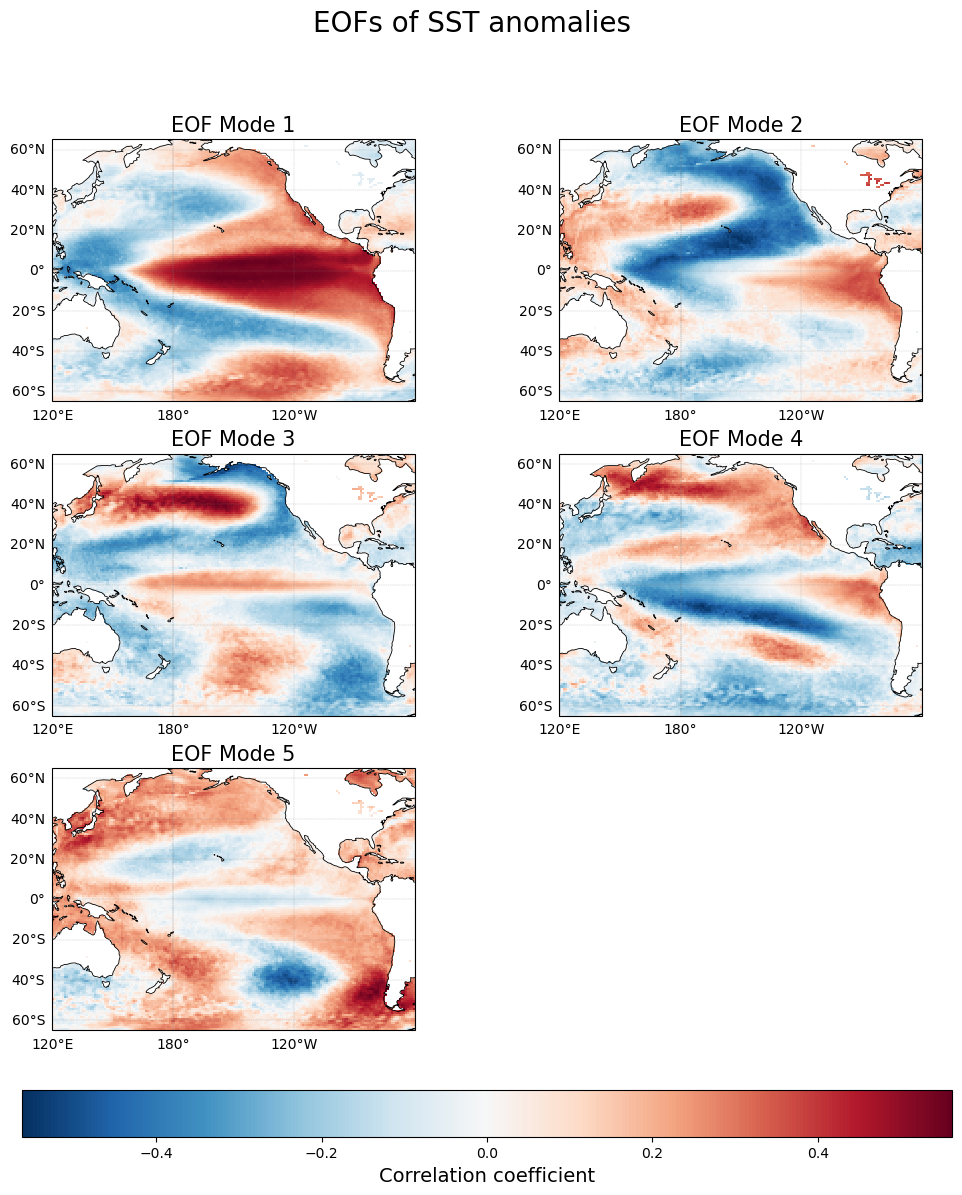

In [ ]:
fig, axes = plt.subplots(
    3, 2, figsize=(12, 13),
    subplot_kw={'projection': ccrs.PlateCarree(central_longitude=190)}
)

im = None
for i in range(5):
    ax = axes.flat[i]
    im = eofs.isel(mode=i).plot(
        ax=ax, cmap='RdBu_r', add_colorbar=False,
        transform=ccrs.PlateCarree()
    )
    ax.set_title(f'EOF Mode {i+1}', fontsize=15)
    ax.coastlines(color='k', linewidth=0.6)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = gl.right_labels = False

axes.flat[5].set_visible(False)

cbar = fig.colorbar(im, ax=axes, orientation="horizontal", fraction=0.05, pad=0.06)
cbar.set_label("Correlation coefficient", fontsize=14)

fig.suptitle("EOFs of SST anomalies", fontsize=20)
plt.show()


### Figure: PC of SST Anomalies

The figures show the time series of the first five PC of SST anomalies in the tropical Pacific.  
The PC figures represent the temporal variability associated with the EOF spatial patterns.
The PC plots do not exhibit any increasing trend as the data had detrend and deseasonalize to avoid result like M04N05

**PC1** captures the strongest variability. We took a sample case from 1997 (the highlighted part) where we have El-Nino event as the ONI index is positive (*https://www.ncei.noaa.gov/access/monitoring/enso/sst*) 
 

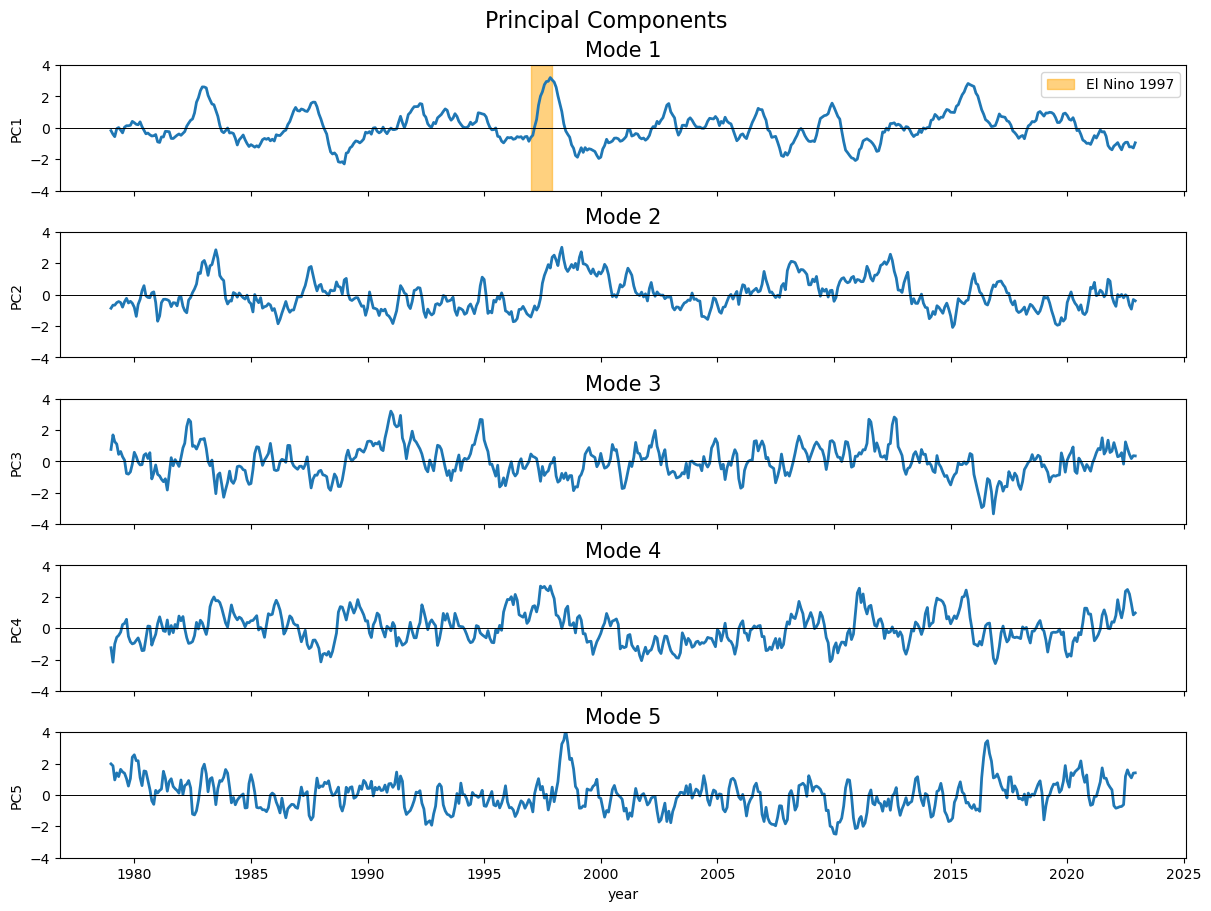

In [33]:
fig, axes = plt.subplots(5, 1, figsize=(12,9), sharex=True, constrained_layout=True)
for i in range(5):
    ax = axes[i]
    pcs.isel(mode=i).plot(ax=ax, linewidth=2)
    ax.axhline(0, color='k', lw=0.7)
    if i == 0:
        ax.axvspan(np.datetime64('1997-01'), np.datetime64('1997-12'),
           color='orange', alpha=0.5, label='El Nino 1997')
        ax.legend(loc='upper right')
        

    ax.set_ylabel(f'PC{i+1}')
    ax.set_ylim(-4, 4)
    ax.set_title(f'Mode {i+1}', fontsize=15)
    

    if i < 4:
        ax.set_xlabel('')
    else:
        ax.set_xlabel('year')
fig.suptitle('Principal Components', fontsize=16)
plt.show()


### Figure: Fraction of Variance

**Mode 1** is dominating and can explain more than 20% of the SST anomalies variability in the Pacific Ocean. \
**Mode 2** being the second place that can explain around 8% of the variability
 

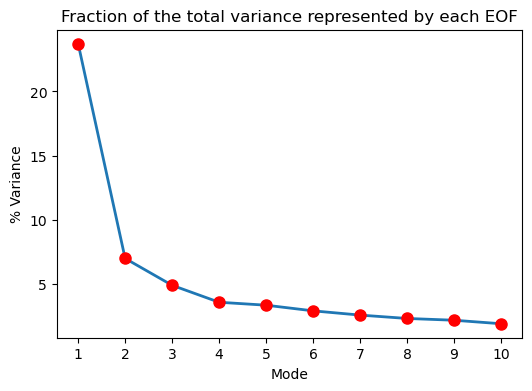

In [26]:
varfrac = solver.varianceFraction(neigs=10) * 100 # Multiply with 100 for percentage

plt.figure(figsize=(6,4))
eof_num = range(1, 11)
plt.plot(eof_num, varfrac[0:15], linewidth=2)
plt.plot(eof_num, varfrac[0:15], linestyle='None', marker="o", color='r', markersize=8)
plt.title('Fraction of the total variance represented by each EOF')
plt.ylabel('% Variance')
plt.xlabel('Mode')
plt.xticks(range(1, 11))
plt.show()

### Figure: The Reconstruction of SST Anomalies

We reconstructed the sst anomalies and plot the standard deviation of SST anomalies for the whole period. \
The reconstruction is using the first five dominant mode by multiplying the EOF dan PC to get the variability. 


**Reconstruction map** shows similar pattern like the **observation map** especially in the equatorial Pacific. \
However in the certain areas such as the western part of the basin does not show a similar pattern for both maps.
**Correlation**: Very high (>0.8) along the equator, showing the first five EOFs capture the observed variability well and skill drops in high latitudes.  


/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_2332785/3195470888.py:52: UserWarning: This f

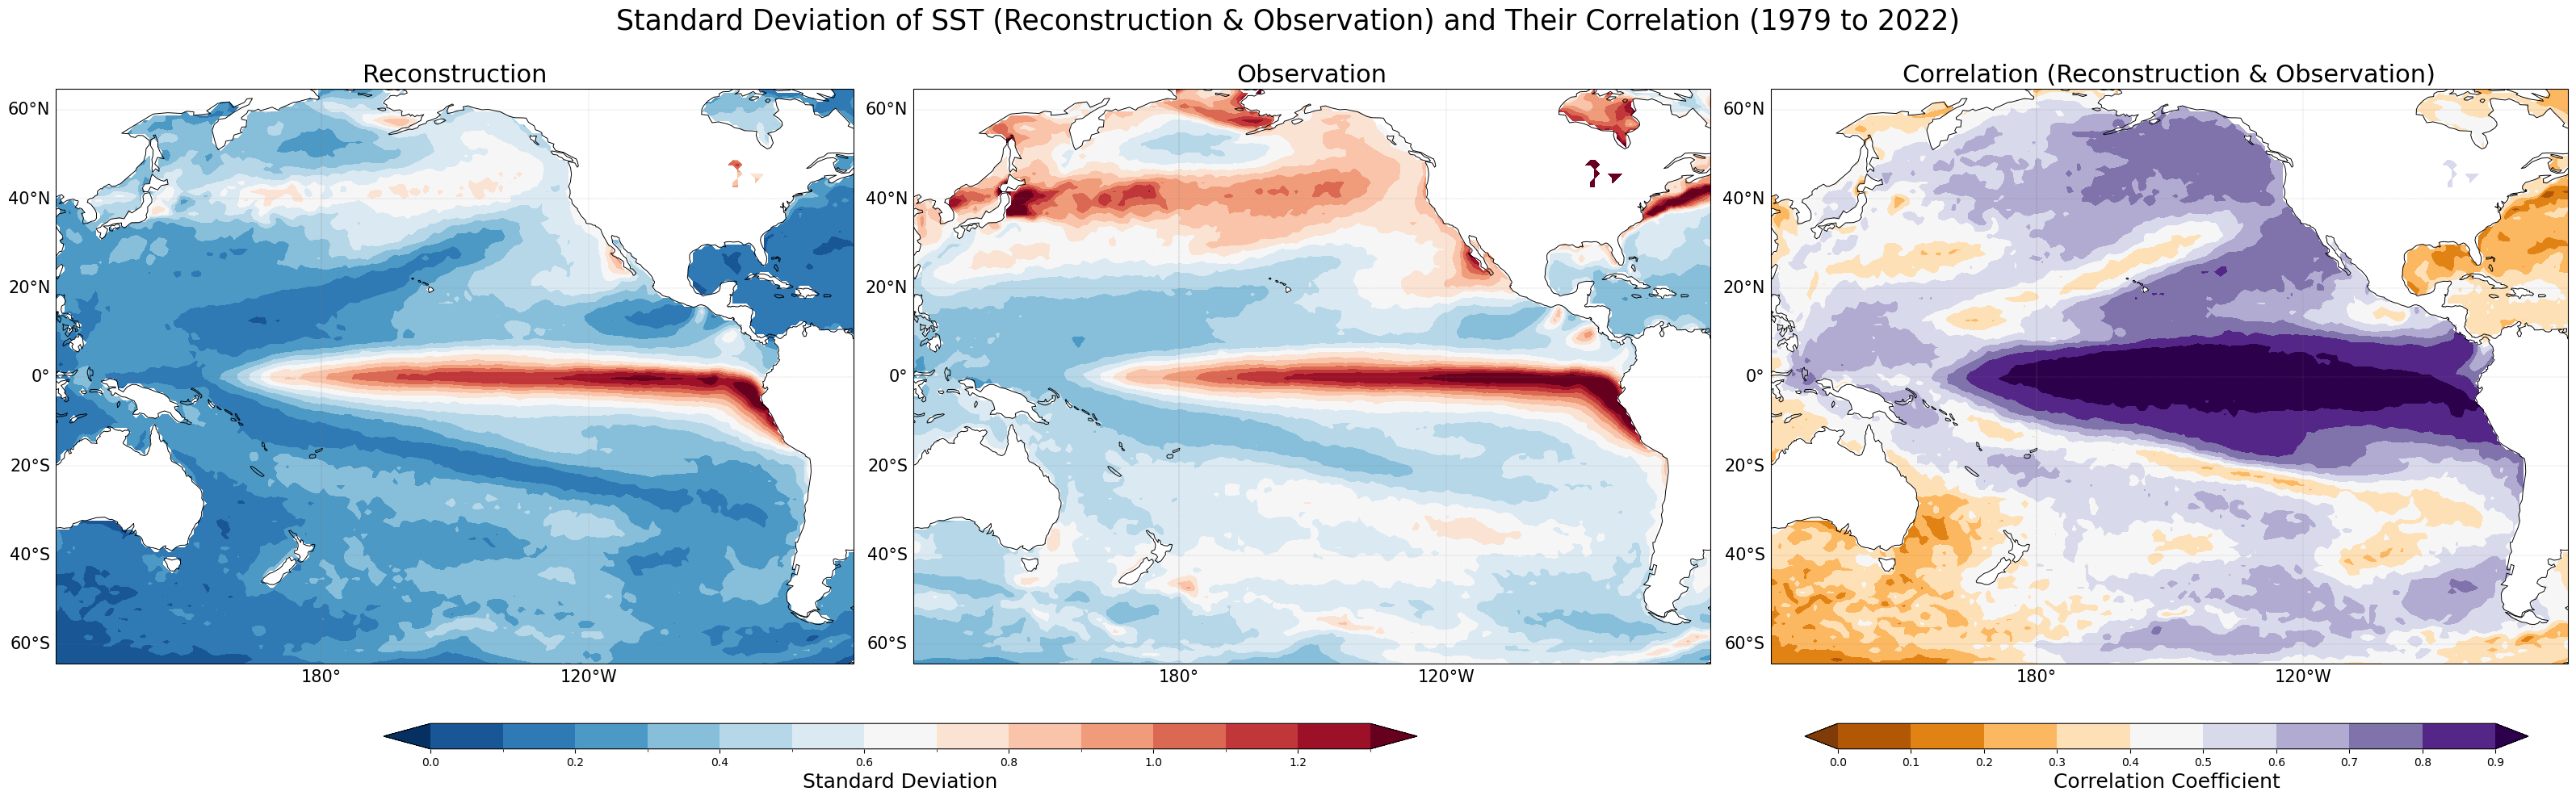

In [64]:
#Calculation fr reconstruction and correlation (using pearson)
sst_recon = solver.reconstructedField(5)
sst_corr = xr.corr(sst_anom, sst_recon, dim='time')

fig, axes = plt.subplots(1, 3, figsize=(32, 9), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=190)})

# Reconstruction
recon = sst_recon.std('time').plot.contourf(
    ax=axes[0], levels=np.arange(0, 1.4, 0.1),
    extend='both', cmap='RdBu_r', add_colorbar=False,
    transform=ccrs.PlateCarree()
)
axes[0].set_title('Reconstruction', fontsize=22)

# Observation
obs = sst_anom.std('time').plot.contourf(
    ax=axes[1], levels=np.arange(0, 1.4, 0.1),
    extend='both', cmap='RdBu_r', add_colorbar=False,
    transform=ccrs.PlateCarree()
)
axes[1].set_title('Observation', fontsize=22)

# Correlation
corr = sst_corr.plot.contourf(
    ax=axes[2], cmap='PuOr', levels=np.arange(0, 1.0, 0.1),
    extend='both', add_colorbar=False,
    transform=ccrs.PlateCarree()
)
axes[2].set_title('Correlation (Reconstruction & Observation)', fontsize=22)

for ax in axes:
    ax.coastlines(color='k', linewidth=0.7)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = gl.ylabel_style = {'size': 15, 'color': 'black'}

# Colorbar for Standard Deviation
cbar_ax = fig.add_axes([0.15, -0.04, 0.4, 0.035])
cbar = fig.colorbar(recon, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Standard Deviation", fontsize=18)

# Colorbar for Correlation
cbar_ax2 = fig.add_axes([0.7, -0.04, 0.28, 0.035])
cbar2 = fig.colorbar(corr, cax=cbar_ax2, orientation="horizontal")
cbar2.set_label("Correlation Coefficient", fontsize=18)

plt.suptitle(
    'Standard Deviation of SST (Reconstruction & Observation) and Their Correlation (1979 to 2022)',
    fontsize=25
)
plt.tight_layout()
plt.show()

### Figure: Correlation between SST EOF1 and Standardized TCWV Anomalies

The correlation show a strong correlation between SST and moisture especially in the equator and **seesaw pattern**. 
Meaning that warming is linked to moistening, while cooling is corresponded to drying. 

**West Pacific**: Negative correlation indicates that when SST anomalies are colder than normal, TCWV also tends to be lower (drier conditions).  
**East Pacific**: Positive correlation indicates that warmer SST anomalies are associated with higher TCWV (more moisture).

/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/data/keeling/a/deffip2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


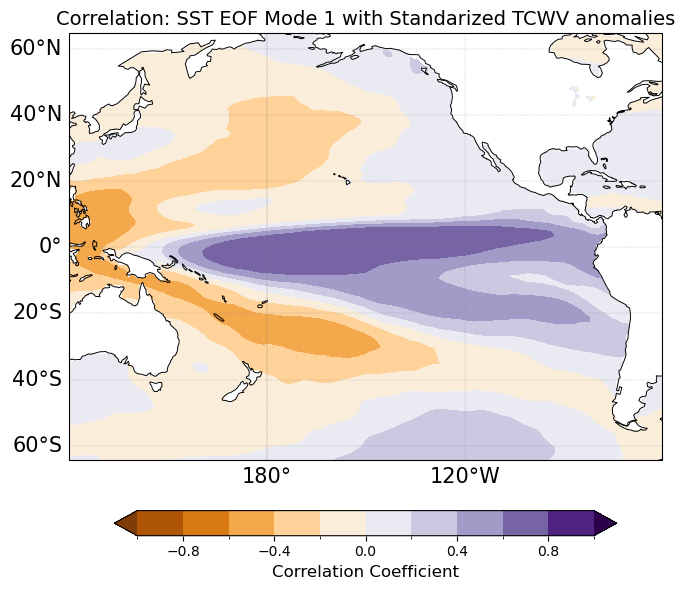

In [67]:
pc1 = pcs.isel(mode=0)

# Standarize the tcwv
tcwv_anom = anom['tcwv']
tcwv_std = (tcwv_anom - tcwv_anom.mean('time')) / tcwv_anom.std('time')

# the correlation between PC1 and TCWV anomalies
corr_map = xr.corr(tcwv_std, pc1, dim='time')

fig, ax = plt.subplots(figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree(central_longitude=190)})

im = corr_map.plot.contourf(
    ax=ax, cmap='PuOr',
    levels=np.arange(-1.0, 1.1, 0.2),
    extend='both',
    transform=ccrs.PlateCarree(),
    add_colorbar=False
)

ax.coastlines(color='k', linewidth=0.7)
gl = ax.gridlines(draw_labels=True, linewidth=0.3,
                  color='gray', alpha=0.5, linestyle='--')
gl.top_labels = gl.right_labels = False
gl.xlabel_style = gl.ylabel_style = {'size': 15, 'color': 'black'}

cbar = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.1)
cbar.set_label("Correlation Coefficient", fontsize=12)

ax.set_title("Correlation: SST EOF Mode 1 with Standarized TCWV anomalies", fontsize=14)

plt.tight_layout()
plt.show()